# Citi Bike project, part 1: data and cleaning

Group 01: William Challma, Thomas Savazzi, Alessandro Simone

## The files we used

| File | What it contains | Where we got it |
|---|---|---|
| `citibike_2025_2026_data.parquet` | every Citi Bike ride from August 2025 to August 2026 (50.8 million rides), built from the 13 monthly files with the code below | Citi Bike System Data, https://citibikenyc.com/system-data (files at https://s3.amazonaws.com/tripdata/index.html) |
| `citi_bike_stations_2025.parquet`, `citi_bike_stations_2026.parquet` | bikes and free docks at every station, saved every 2 minutes from the Citi Bike live feed (about 1 billion rows) | Kaggle, Ethan Rosenthal, https://www.kaggle.com/datasets/rosenthal/citi-bike-stations |
| `weather-2025.csv`, `weather-2026.csv` | daily weather in Central Park: temperature, rain, wind | Meteostat, https://meteostat.net/en/place/us/new-york-city |
| `app_reviews.csv` | the last 500 App Store reviews of the Citi Bike app (US store) | Apple review feed, https://itunes.apple.com/us/rss/customerreviews/page=1/id=641194843/sortby=mostrecent/json (looking at the first 10 pages by changing page in the url)|

The raw files are about 9 GB and the station files alone have more than one billion rows, so they cannot be used in Colab. We ran this notebook on our laptop (VS Code) with the raw files in this folder. It cleans the data and saves small csv files in the `2_Analysis` folder, which is what we use for the analysis.

## Downloading the trips

Citi Bike publishes one zip per month with several csv files inside. We downloaded the 13 months and put all the rides in one parquet file, which is much lighter than the csv files and faster to read. Pandas cannot hold all the csv files in memory, so for this step we used duckdb. We ran this cell only once (it takes about an hour), so it has no output.

In [ ]:
# !pip install duckdb
import urllib.request
import zipfile
import shutil
import duckdb

months = ['202508', '202509', '202510', '202511', '202512', '202601', '202602', '202603', '202604', '202605', '202606', '202607', '202608']

for m in months:
    file = m + '-citibike-tripdata.zip'
    print('downloading', file)
    urllib.request.urlretrieve('https://s3.amazonaws.com/tripdata/' + file, file)
    zipfile.ZipFile(file).extractall('tripdata')

# some zip files also contain hidden mac files
shutil.rmtree('tripdata/__MACOSX', ignore_errors=True)

# station ids are read as text, otherwise ids like 6527.07 become numbers
duckdb.sql("""
    COPY (SELECT * FROM read_csv('tripdata/**/*.csv', union_by_name=true, types={'start_station_id': 'VARCHAR', 'end_station_id': 'VARCHAR'}))
    TO 'citibike_2025_2026_data.parquet' (FORMAT parquet, COMPRESSION zstd)
""")

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pyarrow.parquet as pq

## 1. Trips

The file has 50.8 million rows. Text columns are read as categories (`read_dictionary`): each station name is stored once instead of 50 million times, otherwise the table does not fit in memory.

In [2]:
text_cols = ['rideable_type', 'member_casual', 'start_station_name', 'end_station_name']
other_cols = ['ride_id', 'started_at', 'ended_at', 'start_lat', 'start_lng', 'end_lat', 'end_lng']

trips = pq.read_table('citibike_2025_2026_data.parquet', columns=text_cols + other_cols, read_dictionary=text_cols).to_pandas()
trips.head()

,rideable_type,member_casual,start_station_name,end_station_name,ride_id,started_at,ended_at,start_lat,start_lng,end_lat,end_lng
0,electric_bike,member,75 St & Northern Blvd,Ditmars Blvd & 94 St,1527BC87374D7267,2025-08-05 12:38:34.768,2025-08-05 12:47:13.228,40.754730,-73.891800,40.770200,-73.875870
1,classic_bike,member,Riverside Dr & W 145 St,Riverside Dr E & W 155 St,DB20D4A778A0054A,2025-08-10 20:45:40.270,2025-08-10 20:50:35.171,40.827305,-73.951989,40.834098,-73.948350
2,electric_bike,member,N 7 St & Driggs Ave,Monitor St & Meeker Ave,97EAB930B90356B8,2025-08-08 08:36:41.894,2025-08-08 08:42:58.061,40.716967,-73.956388,40.721226,-73.941845
3,electric_bike,member,Park Ave & E 41 St,E 15 St & 3 Ave,CC3E01200770DA87,2025-08-06 19:09:35.004,2025-08-06 19:20:02.434,40.751581,-73.977910,40.734232,-73.986923
4,electric_bike,member,McKibbin St & Manhattan Ave,N 6 St & Bedford Ave,5BE4BFABDAFCCE5A,2025-08-03 12:28:55.029,2025-08-03 12:37:25.051,40.705109,-73.944073,40.717452,-73.958509


In [3]:
trips.isna().sum()

rideable_type              0
member_casual              0
start_station_name     27433
end_station_name      131729
ride_id                    0
started_at                 0
ended_at                   0
start_lat              27433
start_lng              27433
end_lat               145009
end_lng               145009
dtype: int64

In [4]:
print('first ride:', trips['started_at'].min())
print('last ride:', trips['started_at'].max())

first ride: 2025-07-30 23:00:23.818000
last ride: 2026-08-31 23:58:01.765000


### 1.1 Cleaning rules

Each rule comes from a problem we saw in the data. We keep the number of rows left after each rule, for the table in the report.

In [ ]:
rows = [len(trips)]

# the same ride twice
trips = trips.drop_duplicates(subset='ride_id')
trips = trips.drop(columns='ride_id')
rows.append(len(trips))

# keep 1 Aug 2025 - 31 Aug 2026 (the August file also has some rides of 31 July)
trips = trips[(trips['started_at'] >= '2025-08-01') & (trips['started_at'] < '2026-09-01')]
rows.append(len(trips))

# no start or end station -> bike lost or not docked
trips = trips.dropna(subset=['start_station_name', 'end_station_name', 'end_lat', 'end_lng'])
rows.append(len(trips))

trips['duration_min'] = (trips['ended_at'] - trips['started_at']).dt.total_seconds() / 60

trips = trips[trips['duration_min'] > 0]
rows.append(len(trips))

# under 1 minute ( false start)
trips = trips[trips['duration_min'] >= 1]
rows.append(len(trips))

# over 3 hours -> (bike not docked properly)
trips = trips[trips['duration_min'] <= 180]
rows.append(len(trips))
rows

[50810230, 50809718, 50809428, 50641115, 50640633, 50640629, 50606051]

The last rule uses the distance of the ride. We compute it with the haversine formula in a small function (as in session 1.3). The whole network fits in a square of about 30 km, so a longer straight line means wrong coordinates.

In [6]:
def haversine(lat1, lon1, lat2, lon2):
    ''' distance in km between two points '''
    lat1, lon1, lat2, lon2 = np.radians(lat1), np.radians(lon1), np.radians(lat2), np.radians(lon2)
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

# Times Square -> Brooklyn Bridge, about 5-6 km
haversine(40.758, -73.985, 40.706, -73.997)

np.float64(5.86987791177243)

In [7]:
trips['distance_km'] = haversine(trips['start_lat'], trips['start_lng'], trips['end_lat'], trips['end_lng'])
trips = trips[trips['distance_km'] <= 30]
rows.append(len(trips))

log_trips = pd.DataFrame({'step': ['raw data', 'duplicated ride_id', 'outside Aug 2025 - Aug 2026', 'missing start/end station', 'duration <= 0',
                                   'duration < 1 min', 'duration > 3 hours', 'distance > 30 km (wrong coordinates)'],
                          'rows_left': rows})
log_trips['removed'] = -log_trips['rows_left'].diff()
log_trips['removed_%'] = log_trips['removed'] / rows[0] * 100
log_trips.to_csv('../2_Analysis/cleaning_log_trips.csv', index=False)
log_trips

,step,rows_left,removed,removed_%
0,raw data,50810230,NaN,NaN
1,duplicated ride_id,50809718,512.0,0.001008
2,outside Aug 2025 - Aug 2026,50809428,290.0,0.000571
3,missing start/end station,50641115,168313.0,0.331258
4,duration <= 0,50640633,482.0,0.000949
5,duration < 1 min,50640629,4.0,0.000008
6,duration > 3 hours,50606051,34578.0,0.068053
7,distance > 30 km (wrong coordinates),50606047,4.0,0.000008


In total 204,183 rides are removed (0.4%), mostly rides without a station and rides longer than 3 hours.

### 1.2 New columns

Period of the day: `morning` is 7-10am and `evening` is 4-8pm, the two commuting peaks. We do the same for the end of the ride (arrivals).

In [8]:
trips['date'] = trips['started_at'].dt.normalize()
trips['hour'] = trips['started_at'].dt.hour
trips['weekday'] = trips['started_at'].dt.dayofweek
trips['month'] = trips['started_at'].dt.to_period('M')
trips['is_weekend'] = trips['weekday'] >= 5
trips['round_trip'] = trips['start_station_name'].astype(str) == trips['end_station_name'].astype(str)

trips['period'] = 'other'
trips.loc[(trips['hour'] >= 7) & (trips['hour'] < 10), 'period'] = 'morning'
trips.loc[(trips['hour'] >= 16) & (trips['hour'] < 20), 'period'] = 'evening'

trips['end_date'] = trips['ended_at'].dt.normalize()
trips['end_hour'] = trips['ended_at'].dt.hour
trips['end_period'] = 'other'
trips.loc[(trips['end_hour'] >= 7) & (trips['end_hour'] < 10), 'end_period'] = 'morning'
trips.loc[(trips['end_hour'] >= 16) & (trips['end_hour'] < 20), 'end_period'] = 'evening'

trips[['duration_min', 'distance_km']].describe()

,duration_min,distance_km
count,5.060605e+07,5.060605e+07
mean,1.241634e+01,2.029608e+00
std,1.145582e+01,1.719847e+00
min,1.000033e+00,0.000000e+00
25%,5.355183e+00,8.761347e-01
50%,9.110467e+00,1.521115e+00
75%,1.561405e+01,2.643184e+00
max,1.799986e+02,2.991694e+01


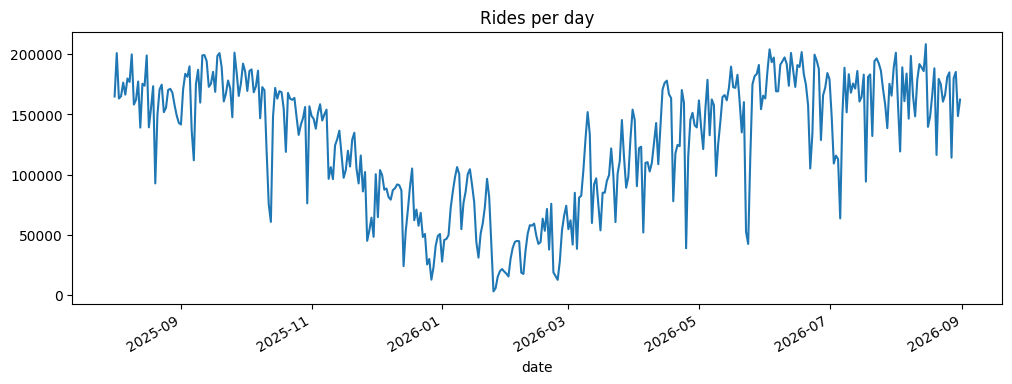

In [9]:
trips.groupby('date').size().plot(figsize=(12, 4))
plt.title('Rides per day')
plt.show()

## 2. Station status

About 1 billion rows, too many for the memory of a laptop. We read the two files in batches of 5 million rows: each batch is cleaned, reduced to counts and then thrown away.

What we keep from each snapshot is whether the station is empty (0 bikes) or full (0 free docks). We count, per station, the snapshots and how many of them were empty or full, once by station, day and period (for `station_day.csv`) and once by station, weekday/weekend and hour (for the hourly profiles in `stations.csv`).

In [10]:
cols = ['station_name', 'fetched_at', 'num_bikes_available', 'num_docks_available', 'capacity', 'is_installed', 'is_renting', 'is_returning']

# first rows of the 2025 file
next(pq.ParquetFile('citi_bike_stations_2025.parquet').iter_batches(batch_size=5, columns=cols)).to_pandas()

,station_name,fetched_at,num_bikes_available,num_docks_available,capacity,is_installed,is_renting,is_returning
0,28 Ave & 44 St,2025-01-01 00:00:22+00:00,7,6,15,True,True,True
1,28 Ave & 44 St,2025-01-01 00:02:22+00:00,7,6,15,True,True,True
2,28 Ave & 44 St,2025-01-01 00:04:22+00:00,7,6,15,True,True,True
3,28 Ave & 44 St,2025-01-01 00:06:22+00:00,7,6,15,True,True,True
4,28 Ave & 44 St,2025-01-01 00:08:22+00:00,7,6,15,True,True,True


The cleaning rules are: snapshot outside our period (the 2025 file starts in January, the 2026 file ends in September), duplicated snapshot, missing or zero capacity, and station not in service (when a station is closed, 0 bikes does not mean it was emptied by riders). Times are in UTC so we convert them to New York time first.

In [11]:
n_raw = 0
removed = {'outside Aug 2025 - Aug 2026': 0, 'duplicated poll': 0, 'missing or zero capacity': 0, 'station not in service': 0}
day_parts = []
hour_parts = []

for file in ['citi_bike_stations_2025.parquet', 'citi_bike_stations_2026.parquet']:
    for batch in pq.ParquetFile(file).iter_batches(batch_size=5_000_000, columns=cols):
        s = batch.to_pandas()
        n_raw += len(s)

        s['time'] = s['fetched_at'].dt.tz_convert('America/New_York').dt.tz_localize(None)
        keep = (s['time'] >= '2025-08-01') & (s['time'] < '2026-09-01')
        removed['outside Aug 2025 - Aug 2026'] += (~keep).sum()
        s = s[keep]

        n = len(s)
        s = s.drop_duplicates(subset=['station_name', 'fetched_at'])
        removed['duplicated poll'] += n - len(s)

        keep = s['capacity'] > 0
        removed['missing or zero capacity'] += (~keep).sum()
        s = s[keep]

        keep = (s['is_installed'] == True) & (s['is_renting'] == True) & (s['is_returning'] == True)
        removed['station not in service'] += (~keep).sum()
        s = s[keep]

        s['date'] = s['time'].dt.normalize()
        s['hour'] = s['time'].dt.hour
        s['is_weekend'] = s['time'].dt.dayofweek >= 5
        s['empty'] = s['num_bikes_available'] == 0
        s['full'] = s['num_docks_available'] == 0
        s['period'] = 'other'
        s.loc[(s['hour'] >= 7) & (s['hour'] < 10), 'period'] = 'morning'
        s.loc[(s['hour'] >= 16) & (s['hour'] < 20), 'period'] = 'evening'

        day_parts.append(s.groupby(['station_name', 'date', 'period']).agg(polls=('empty', 'size'), empty=('empty', 'sum'), full=('full', 'sum'), capacity=('capacity', 'max')))
        hour_parts.append(s.groupby(['station_name', 'is_weekend', 'hour']).agg(polls=('empty', 'size'), empty=('empty', 'sum'), full=('full', 'sum')))

print('raw rows:', n_raw)
removed

raw rows: 1062555330


{'outside Aug 2025 - Aug 2026': np.int64(389725997),
 'duplicated poll': 2353083,
 'missing or zero capacity': np.int64(8005532),
 'station not in service': np.int64(19526307)}

In [12]:
rows = [n_raw]
rows.append(rows[-1] - removed['outside Aug 2025 - Aug 2026'])
rows.append(rows[-1] - removed['duplicated poll'])
rows.append(rows[-1] - removed['missing or zero capacity'])
rows.append(rows[-1] - removed['station not in service'])

log_status = pd.DataFrame({'step': ['raw data'] + list(removed.keys()), 'rows_left': rows})
log_status['removed'] = -log_status['rows_left'].diff()
log_status['removed_%'] = log_status['removed'] / rows[0] * 100
log_status.to_csv('../2_Analysis/cleaning_log_status.csv', index=False)
log_status

,step,rows_left,removed,removed_%
0,raw data,1062555330,NaN,NaN
1,outside Aug 2025 - Aug 2026,672829333,389725997.0,36.678184
2,duplicated poll,670476250,2353083.0,0.221455
3,missing or zero capacity,662470718,8005532.0,0.753423
4,station not in service,642944411,19526307.0,1.837674


A station or a day can be cut between two batches, so we add up the counts once more. Then we go from counts to percentages: `pct_empty_morning` is the share of the 7-10am snapshots in which the station had no bike.

In [13]:
status_day = pd.concat(day_parts).groupby(['station_name', 'date', 'period']).agg(
    polls=('polls', 'sum'), empty=('empty', 'sum'), full=('full', 'sum'), capacity=('capacity', 'max')).reset_index()
status_hour = pd.concat(hour_parts).groupby(['station_name', 'is_weekend', 'hour']).sum().reset_index()

status_day['pct_empty'] = status_day['empty'] / status_day['polls'] * 100
status_day['pct_full'] = status_day['full'] / status_day['polls'] * 100

# one column per period: pct_empty_morning, pct_empty_evening, ...
wide = status_day.pivot_table(index=['station_name', 'date'], columns='period', values=['pct_empty', 'pct_full'])
wide.columns = [a + '_' + b for a, b in wide.columns]
wide = wide.drop(columns=['pct_empty_other', 'pct_full_other'])

whole_day = status_day.groupby(['station_name', 'date']).agg(polls=('polls', 'sum'), empty=('empty', 'sum'), full=('full', 'sum'), capacity=('capacity', 'max'))
whole_day['pct_empty_day'] = whole_day['empty'] / whole_day['polls'] * 100
whole_day['pct_full_day'] = whole_day['full'] / whole_day['polls'] * 100

status_wide = whole_day[['capacity', 'polls', 'pct_empty_day', 'pct_full_day']].join(wide).reset_index()
status_wide.head()

,station_name,date,capacity,polls,pct_empty_day,pct_full_day,pct_empty_evening,pct_empty_morning,pct_full_evening,pct_full_morning
0,1 Ave & E 110 St,2025-08-01,25.0,720,0.0,14.027778,0.0,0.0,15.833333,0.0
1,1 Ave & E 110 St,2025-08-02,25.0,720,0.0,11.250000,0.0,0.0,0.000000,0.0
2,1 Ave & E 110 St,2025-08-03,25.0,720,0.0,5.416667,0.0,0.0,0.000000,0.0
3,1 Ave & E 110 St,2025-08-04,25.0,720,0.0,0.555556,0.0,0.0,0.000000,0.0
4,1 Ave & E 110 St,2025-08-05,25.0,720,0.0,5.972222,0.0,0.0,3.333333,0.0


## 3. Station-day table

One row is one station on one day, with its status (from part 2), its departures and arrivals (from part 1), the weather and a holiday flag.

In [14]:
dep = trips.groupby(['start_station_name', 'date', 'period'], observed=True).size().unstack(fill_value=0)
dep.columns = ['dep_' + c for c in dep.columns]
dep['departures'] = dep.sum(axis=1)
dep.index.names = ['station_name', 'date']
dep = dep.reset_index()
dep['station_name'] = dep['station_name'].astype(str)

arr = trips.groupby(['end_station_name', 'end_date', 'end_period'], observed=True).size().unstack(fill_value=0)
arr.columns = ['arr_' + c for c in arr.columns]
arr['arrivals'] = arr.sum(axis=1)
arr.index.names = ['station_name', 'date']
arr = arr.reset_index()
arr['station_name'] = arr['station_name'].astype(str)
dep.head()

,station_name,date,dep_evening,dep_morning,dep_other,departures
0,75 St & Northern Blvd,2025-08-01,0,3,9,12
1,75 St & Northern Blvd,2025-08-02,1,1,7,9
2,75 St & Northern Blvd,2025-08-03,4,0,11,15
3,75 St & Northern Blvd,2025-08-04,2,3,4,9
4,75 St & Northern Blvd,2025-08-05,4,3,3,10


The two sources are joined on the station name, because the station ids are not the same in the two files.

In [15]:
print('stations in the trips:', dep['station_name'].nunique())
print('stations in the status:', status_wide['station_name'].nunique())
print('stations in both:', len(set(dep['station_name']) & set(status_wide['station_name'])))

stations in the trips: 2399
stations in the status: 2504
stations in both: 2389


In [16]:
station_day = status_wide.merge(dep, on=['station_name', 'date'], how='left').merge(arr, on=['station_name', 'date'], how='left')
count_cols = ['dep_evening', 'dep_morning', 'dep_other', 'departures', 'arr_evening', 'arr_morning', 'arr_other', 'arrivals']
station_day[count_cols] = station_day[count_cols].fillna(0)
print('station-days:', len(station_day))

station-days: 901753


Two more rules at this level. Incomplete days: fewer than 360 snapshots (half a day) or no snapshot in the morning or evening peak, so the share of time empty is not reliable. Inactive stations: fewer than 365 departures in the whole year, less than one a day.

In [17]:
rows = [len(station_day)]

station_day = station_day[station_day['polls'] >= 360]
station_day = station_day.dropna(subset=['pct_empty_morning', 'pct_empty_evening'])
rows.append(len(station_day))

total_dep = station_day.groupby('station_name')['departures'].sum()
active = total_dep[total_dep >= 365].index
station_day = station_day[station_day['station_name'].isin(active)]
rows.append(len(station_day))

log_station_day = pd.DataFrame({'step': ['station-days after joining', 'incomplete day (< 360 polls or no peak data)', 'inactive station (< 365 departures)'],
                                'rows_left': rows})
log_station_day['removed'] = -log_station_day['rows_left'].diff()
log_station_day.to_csv('../2_Analysis/cleaning_log_station_day.csv', index=False)
print('stations kept:', station_day['station_name'].nunique())
log_station_day

stations kept: 2318


,step,rows_left,removed
0,station-days after joining,901753,NaN
1,incomplete day (< 360 polls or no peak data),892347,9406.0
2,inactive station (< 365 departures),851613,40734.0


### Weather and holidays

The weather files have a hidden character at the start (BOM), which `encoding='utf-8-sig'` removes. `snow`, `wdir`, `wpgt` and `tsun` are always empty and `pres` is not needed, so we keep only temperature, rain and wind. The few days without temperature or rain stay as NaN and are dropped only in the models that use the weather.

In [18]:
weather = pd.concat([pd.read_csv('weather-2025.csv', encoding='utf-8-sig'), pd.read_csv('weather-2026.csv', encoding='utf-8-sig')], ignore_index=True)
weather.isna().sum()

date      0
tavg      5
tmin      6
tmax      6
prcp     13
snow    638
wdir    638
wspd      0
wpgt    638
pres    158
tsun    638
dtype: int64

In [19]:
weather['date'] = pd.to_datetime(weather['date'])
weather = weather[(weather['date'] >= '2025-08-01') & (weather['date'] < '2026-09-01')]
weather = weather[['date', 'tavg', 'tmin', 'tmax', 'prcp', 'wspd']]
weather.to_csv('../2_Analysis/weather_clean.csv', index=False)
weather.describe()

,date,tavg,tmin,tmax,prcp,wspd
count,396,396.000000,395.000000,395.000000,391.000000,396.000000
mean,2026-02-14 12:00:00,14.562626,11.053671,18.793165,1.118414,9.017929
min,2025-08-01 00:00:00,-9.100000,-15.200000,-6.000000,0.000000,2.200000
25%,2025-11-07 18:00:00,5.875000,2.900000,10.000000,0.000000,5.500000
50%,2026-02-14 12:00:00,15.550000,12.200000,20.600000,0.000000,8.100000
75%,2026-05-24 06:00:00,23.700000,20.000000,28.000000,0.600000,11.400000
max,2026-08-31 00:00:00,32.900000,26.700000,38.900000,57.200000,28.500000
std,NaN,9.933904,9.805645,10.426885,4.388671,4.764782


In [20]:
from pandas.tseries.holiday import USFederalHolidayCalendar
holidays = USFederalHolidayCalendar().holidays(start='2025-08-01', end='2026-08-31')

station_day = station_day.merge(weather[['date', 'tavg', 'prcp', 'wspd']], on='date', how='left')
station_day['weekday'] = station_day['date'].dt.dayofweek
station_day['month'] = station_day['date'].dt.month
station_day['is_weekend'] = station_day['weekday'] >= 5
station_day['holiday'] = station_day['date'].isin(holidays)

station_day = station_day.round(2)
station_day = station_day.sort_values(['station_name', 'date'])
station_day.to_csv('../2_Analysis/station_day.csv', index=False)
station_day.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 851613 entries, 0 to 851612
Data columns (total 25 columns):
 #   Column             Non-Null Count   Dtype         
---  ------             --------------   -----         
 0   station_name       851613 non-null  object        
 1   date               851613 non-null  datetime64[us]
 2   capacity           851613 non-null  float64       
 3   polls              851613 non-null  int64         
 4   pct_empty_day      851613 non-null  float64       
 5   pct_full_day       851613 non-null  float64       
 6   pct_empty_evening  851613 non-null  float64       
 7   pct_empty_morning  851613 non-null  float64       
 8   pct_full_evening   851613 non-null  float64       
 9   pct_full_morning   851613 non-null  float64       
 10  dep_evening        851613 non-null  float64       
 11  dep_morning        851613 non-null  float64       
 12  dep_other          851613 non-null  float64       
 13  departures         851613 non-null  float64 

## 4. Station table

One row per station, with its weekday profile over 24 hours: the share of its departures and arrivals at each hour (`dep_0` to `dep_23`, `arr_0` to `arr_23`) and the share of time it is empty or full at each hour. This is what we use for the clustering. We also add the position, capacity, total rides, share of casual riders and average duration.

In [21]:
weekday_trips = trips[trips['is_weekend'] == False]

dep_profile = pd.crosstab(weekday_trips['start_station_name'], weekday_trips['hour'], normalize='index')
dep_profile.columns = ['dep_' + str(h) for h in dep_profile.columns]
arr_profile = pd.crosstab(weekday_trips['end_station_name'], weekday_trips['end_hour'], normalize='index')
arr_profile.columns = ['arr_' + str(h) for h in arr_profile.columns]

wk = status_hour[status_hour['is_weekend'] == False].copy()
wk['pct_empty'] = wk['empty'] / wk['polls'] * 100
wk['pct_full'] = wk['full'] / wk['polls'] * 100
empty_profile = wk.pivot(index='station_name', columns='hour', values='pct_empty')
empty_profile.columns = ['empty_' + str(h) for h in empty_profile.columns]
full_profile = wk.pivot(index='station_name', columns='hour', values='pct_full')
full_profile.columns = ['full_' + str(h) for h in full_profile.columns]

In [22]:
info = trips.groupby('start_station_name', observed=True).agg(lat=('start_lat', 'median'), lng=('start_lng', 'median'),
                                                               departures=('duration_min', 'size'), avg_duration=('duration_min', 'mean'),
                                                               casual_share=('member_casual', lambda x: (x == 'casual').mean()),
                                                               round_trip_share=('round_trip', 'mean'))
info['arrivals'] = trips['end_station_name'].value_counts()
info['net_flow'] = info['arrivals'] - info['departures']
info.index = info.index.astype(str)
dep_profile.index = dep_profile.index.astype(str)
arr_profile.index = arr_profile.index.astype(str)

capacity = station_day.groupby('station_name')['capacity'].median()

stations = info.join(capacity).join(dep_profile).join(arr_profile).join(empty_profile).join(full_profile)
stations = stations[stations.index.isin(station_day['station_name'].unique())]
stations.index.name = 'station_name'
stations = stations.round(4)
stations.to_csv('../2_Analysis/stations.csv')
print(stations.shape, 'missing values:', stations.isna().sum().sum())
stations.head()

(2318, 105) missing values: 0


,lat,lng,departures,avg_duration,casual_share,round_trip_share,arrivals,net_flow,capacity,dep_0,...,full_14,full_15,full_16,full_17,full_18,full_19,full_20,full_21,full_22,full_23
station_name,,,,,,,,,,,,,,,,,,,,,
75 St & Northern Blvd,40.7547,-73.8918,2576,9.7336,0.1801,0.0318,2613,37,18.0,0.0166,...,0.6548,0.3571,0.3571,0.4166,1.0237,1.0475,1.5542,1.8861,2.1352,2.7402
Riverside Dr & W 145 St,40.8273,-73.9520,10903,16.7897,0.2136,0.0400,10472,-431,35.0,0.0075,...,0.0000,0.0000,0.2500,0.0833,0.3095,0.2742,0.0474,0.3559,0.2847,0.0000
N 7 St & Driggs Ave,40.7170,-73.9564,114852,9.3778,0.1489,0.0093,113489,-1363,53.0,0.0113,...,10.6881,7.0895,4.0314,2.5582,3.8215,5.2892,4.5951,3.1175,1.0072,0.2039
Park Ave & E 41 St,40.7516,-73.9779,54778,13.0206,0.1491,0.0080,53297,-1481,109.0,0.0041,...,4.6938,5.0143,4.2173,2.2026,0.7270,0.6432,0.3677,0.0475,0.0119,0.2620
McKibbin St & Manhattan Ave,40.7051,-73.9441,20201,12.7098,0.1608,0.0148,20320,119,23.0,0.0090,...,0.2969,0.2294,0.0810,0.0810,0.2159,1.4303,5.5780,9.5833,11.2500,18.1720


## 5. Sample of rides

For the member vs casual models we do not need 50 million rides. We take 0.4% of the rides of each month and rider type (stratified sample, 26 groups), so the sample keeps the seasonality and the 18% share of casual riders. `random_state=42` so that the sample can be reproduced. The classes are not rebalanced here: SMOTE is done later on the training set only.

In [23]:
sample = trips.groupby(['month', 'member_casual'], observed=True).sample(frac=0.004, random_state=42)
print('rows in the sample:', len(sample))

rows in the sample: 202423


Check on the variables we did not use to stratify: the shares in the sample are the same as in the full data.

In [24]:
check = []
for col in ['member_casual', 'rideable_type', 'is_weekend', 'round_trip', 'period']:
    table = pd.DataFrame({'population': trips[col].value_counts(normalize=True), 'sample': sample[col].value_counts(normalize=True)})
    table['variable'] = col
    check.append(table)
check = pd.concat(check)
check['difference'] = check['sample'] - check['population']
check.to_csv('../2_Analysis/sample_check.csv')
check

,population,sample,variable,difference
member,0.821922,0.821922,member_casual,2.195302e-08
casual,0.178078,0.178078,member_casual,-2.195302e-08
electric_bike,0.717614,0.717389,rideable_type,-2.255647e-04
classic_bike,0.282386,0.282611,rideable_type,2.255647e-04
False,0.732122,0.733652,is_weekend,1.529815e-03
True,0.267878,0.266348,is_weekend,-1.529815e-03
False,0.979297,0.979276,round_trip,-2.075157e-05
True,0.020703,0.020724,round_trip,2.075157e-05
other,0.526576,0.525429,period,-1.146463e-03
evening,0.317961,0.318521,period,5.602809e-04


In [25]:
pd.DataFrame({'population': trips[['duration_min', 'distance_km']].describe().stack(),
              'sample': sample[['duration_min', 'distance_km']].describe().stack()})

population         sample
count duration_min  5.060605e+07  202423.000000
      distance_km   5.060605e+07  202423.000000
mean  duration_min  1.241634e+01      12.371615
      distance_km   2.029608e+00       2.022000
std   duration_min  1.145582e+01      11.357517
      distance_km   1.719847e+00       1.707009
min   duration_min  1.000033e+00       1.002067
      distance_km   0.000000e+00       0.000000
25%   duration_min  5.355183e+00       5.344942
      distance_km   8.761347e-01       0.875267
50%   duration_min  9.110467e+00       9.066850
      distance_km   1.521115e+00       1.516643
75%   duration_min  1.561405e+01      15.590442
      distance_km   2.643184e+00       2.633755
max   duration_min  1.799986e+02     179.816283
      distance_km   2.991694e+01      24.455048

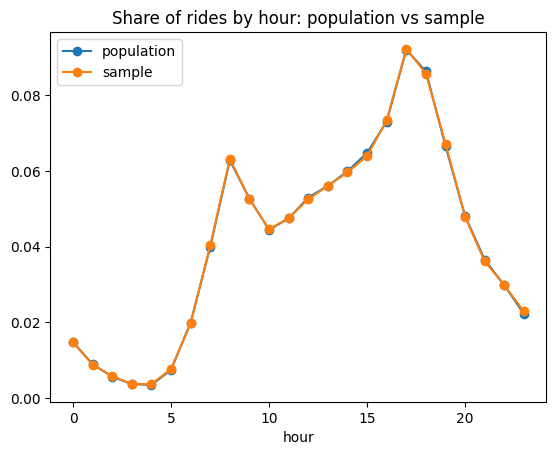

In [26]:
hours = pd.DataFrame({'population': trips['hour'].value_counts(normalize=True), 'sample': sample['hour'].value_counts(normalize=True)}).sort_index()
hours.plot(marker='o')
plt.title('Share of rides by hour: population vs sample')
plt.show()

In [27]:
sample['month'] = sample['month'].astype(str)
sample = sample.merge(weather[['date', 'tavg', 'prcp']], on='date', how='left')
sample['holiday'] = sample['date'].isin(holidays)

sample = sample[['started_at', 'date', 'month', 'weekday', 'hour', 'is_weekend', 'holiday', 'period',
                 'member_casual', 'rideable_type', 'duration_min', 'distance_km', 'round_trip',
                 'start_station_name', 'end_station_name', 'start_lat', 'start_lng', 'tavg', 'prcp']]
sample.to_csv('../2_Analysis/trips_sample.csv', index=False)
sample.head()

,started_at,date,month,weekday,hour,is_weekend,holiday,period,member_casual,rideable_type,duration_min,distance_km,round_trip,start_station_name,end_station_name,start_lat,start_lng,tavg,prcp
0,2025-08-06 07:45:35.735,2025-08-06,2025-08,2,7,False,False,morning,member,electric_bike,11.011017,2.443089,False,W 56 St & 10 Ave,W 27 St & 7 Ave,40.768254,-73.988639,23.8,1.1
1,2025-08-29 08:05:43.088,2025-08-29,2025-08,4,8,False,False,morning,member,classic_bike,9.714683,0.847103,False,W 20 St & 7 Ave,Broadway & W 29 St,40.742388,-73.997262,22.3,1.5
2,2025-08-26 17:11:12.707,2025-08-26,2025-08,1,17,False,False,evening,member,electric_bike,13.590400,3.647267,False,Broadway & Whipple St,Eastern Pkwy & Troy Ave,40.701666,-73.943730,23.1,0.0
3,2025-08-17 15:40:56.360,2025-08-17,2025-08,6,15,True,False,other,member,classic_bike,16.203117,2.426017,False,Broadway & Morris St,Pier 40 - Hudson River Park,40.705945,-74.013219,26.8,1.4
4,2025-08-24 10:51:06.568,2025-08-24,2025-08,6,10,True,False,other,member,classic_bike,10.005567,1.094012,False,Grand St & Elizabeth St,MacDougal St & Prince St,40.718822,-73.995960,23.4,0.0


## 6. App reviews

Only a light cleaning here. The text itself (stopwords, lemmatization) is cleaned in the analysis, as in session 5.4. We drop the author name.

In [28]:
reviews = pd.read_csv('app_reviews.csv')
print('reviews:', len(reviews), ' missing text:', reviews['content'].isna().sum(), ' duplicated ids:', reviews['id'].duplicated().sum())

reviews = reviews.dropna(subset=['content']).drop_duplicates(subset='id')
reviews['date'] = pd.to_datetime(reviews['date'], utc=True).dt.tz_convert('America/New_York').dt.date
reviews = reviews[['id', 'date', 'rating', 'title', 'content', 'version']]
reviews.to_csv('../2_Analysis/reviews_clean.csv', index=False)
reviews.head()

reviews: 500  missing text: 0  duplicated ids: 0


,id,date,rating,title,content,version
0,14593055452,2026-09-25,5,Gratitude For The Discount Program,Deep Gratitude and Appreciation for the discou...,2026.36.3
1,14584357201,2026-09-23,5,:),I love CB,2026.36.3
2,14584292101,2026-09-23,1,Lazy monopoly,First of all this app sucks. They want feedbac...,2026.36.3
3,14577678495,2026-09-21,2,Needs a way to send feedback,The only way there is to give feedback is to g...,2026.36.3
4,14576684751,2026-09-21,4,Bike availability,"During g busy times, please bring bikes back t...",2026.35.3
